# Tratamento dos dados e Parte I - Análise Estrutural Obrigatória

**Grafo:** `p2p-Gnutella06` (SNAP) - rede P2P Gnutella de 6/ago/2002 (vértices = hosts, arestas = conexões).

**Ordem de execução do repositório:** 01 -> 02 -> 03. Este notebook gera data/processed/*.edgelist, que os outros dois leem.

**O que este notebook faz**
1. Auditoria e tratamento do grafo bruto (multigrafo -> simples, auto-loops, componente conexa).
2. Todas as métricas da Parte I + tabela de controle (computada / não computada).
3. Distribuição de graus (linear e log-log) e visualização reduzida do grafo.
4. Validação cruzada com as estatísticas publicadas pelo SNAP.

In [1]:
import gzip, random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra as sp_dijkstra

SEED = 42
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = ROOT_DIR / "data" / "raw" / "p2p-Gnutella06.txt.gz"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
FIGURES_DIR = ROOT_DIR / "figures"
TABLES_DIR = ROOT_DIR / "results"
for d in (PROCESSED_DIR, FIGURES_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
print("Raiz do projeto:", ROOT_DIR)

Raiz do projeto: d:\Users\lucca\desktop\UFBA\Teoria dos Grafos\Trabalho\SNAP-Trabalho-Grafos-Lucca


## 1. Grafo bruto, auditoria e tratamento

In [2]:
# Abrimos o arquivo comprimido (.gz) e carregamos primeiro como MultiDiGraph.
# Usar um multigrafo na leitura é proposital: assim conseguimos enxergar se existem
# arestas repetidas (paralelas) no arquivo original antes de limpar os dados.
G_raw = nx.MultiDiGraph()
linhas_dados = 0
with gzip.open(RAW_FILE, "rt", encoding="utf-8") as f:
    for linha in f:
        # Pula linhas em branco e o cabeçalho de comentários do SNAP (que começa com '#')
        if linha.startswith("#") or not linha.strip():
            continue
        u, v = map(int, linha.split())
        G_raw.add_edge(u, v)
        linhas_dados += 1

# Conta quantos auto-loops (arestas de um nó para ele mesmo, u -> u) vieram no arquivo
n_loops = sum(1 for _ in nx.selfloop_edges(G_raw))
print("--- AUDITORIA DO GRAFO BRUTO ---")
print(f"Linhas de dados lidas: {linhas_dados}")
print(f"Vértices: {G_raw.number_of_nodes()} | Arestas (multigrafo): {G_raw.number_of_edges()}")
print(f"Auto-loops: {n_loops}")

# T1: Converte de multigrafo para grafo direcionado simples (DiGraph).
# Na conversão, qualquer aresta duplicada entre o mesmo par (u, v) é descartada automaticamente.
G_dir = nx.DiGraph(G_raw)
n_paralelas = G_raw.number_of_edges() - G_dir.number_of_edges()
print(f"Arestas paralelas removidas: {n_paralelas}")

# T2: Remove os auto-loops
G_dir.remove_edges_from(list(nx.selfloop_edges(G_dir)))

# T3: Verifica as componentes fracamente conexas (olhando a rede sem o sentido das setas).
# Se o grafo fosse desconexo, manteríamos só a maior componente para conseguir calcular
# diâmetro, raio e caminhos mínimos sem esbarrar em distâncias infinitas.
wccs = sorted(nx.weakly_connected_components(G_dir), key=len, reverse=True)
print(f"Componentes fracamente conexas: {len(wccs)} | maior: {len(wccs[0])} vértices")
if len(wccs) > 1:
    G_dir = G_dir.subgraph(wccs[0]).copy()
    print(f"-> mantida apenas a maior WCC: {G_dir.number_of_nodes()} vértices")
else:
    print("-> grafo já é fracamente conexo; nenhuma extração necessária.")

# T4: Gera também uma cópia não direcionada (Graph) a partir do grafo já limpo.
G_undir = G_dir.to_undirected()
print("\n--- GRAFOS TRATADOS ---")
print(f"Direcionado:     {G_dir.number_of_nodes()} vértices | {G_dir.number_of_edges()} arestas")
print(f"Não direcionado: {G_undir.number_of_nodes()} vértices | {G_undir.number_of_edges()} arestas")

# Reciprocidade: quantas arestas u->v têm também v->u
n_reciprocas = sum(1 for u, v in G_dir.edges() if G_dir.has_edge(v, u))
print(f"Arestas direcionadas com reversa (u->v e v->u): {n_reciprocas}")

# Salva as duas versões tratadas em disco (lista de arestas) para serem carregadas
# pelos próximos notebooks e ficarem disponíveis no repositório do trabalho.
nx.write_edgelist(G_dir, PROCESSED_DIR / "gnutella06_directed_clean.edgelist", data=False)
nx.write_edgelist(G_undir, PROCESSED_DIR / "gnutella06_undirected_clean.edgelist", data=False)
print("\nSalvo em", PROCESSED_DIR)

# Exporta um resumo numérico de toda essa auditoria para usarmos direto na tabela do relatório
pd.DataFrame([
    {"Item": "Linhas de dados no arquivo", "Valor": linhas_dados},
    {"Item": "Vértices brutos", "Valor": G_raw.number_of_nodes()},
    {"Item": "Arestas brutas", "Valor": G_raw.number_of_edges()},
    {"Item": "Auto-loops removidos", "Valor": n_loops},
    {"Item": "Arestas paralelas removidas", "Valor": n_paralelas},
    {"Item": "Componentes fracamente conexas (antes da extração)", "Valor": len(wccs)},
    {"Item": "Vértices finais", "Valor": G_dir.number_of_nodes()},
    {"Item": "Arestas direcionadas finais", "Valor": G_dir.number_of_edges()},
    {"Item": "Arestas não direcionadas finais", "Valor": G_undir.number_of_edges()},
    {"Item": "Arestas recíprocas (dirigidas)", "Valor": n_reciprocas},
]).to_csv(TABLES_DIR / "tabela_tratamento.csv", index=False)

--- AUDITORIA DO GRAFO BRUTO ---
Linhas de dados lidas: 31525
Vértices: 8717 | Arestas (multigrafo): 31525
Auto-loops: 0
Arestas paralelas removidas: 0
Componentes fracamente conexas: 1 | maior: 8717 vértices
-> grafo já é fracamente conexo; nenhuma extração necessária.

--- GRAFOS TRATADOS ---
Direcionado:     8717 vértices | 31525 arestas
Não direcionado: 8717 vértices | 31525 arestas
Arestas direcionadas com reversa (u->v e v->u): 0

Salvo em d:\Users\lucca\desktop\UFBA\Teoria dos Grafos\Trabalho\SNAP-Trabalho-Grafos-Lucca\data\processed


## 2. Parte I - Métricas estruturais

In [3]:
# Converte o grafo do NetworkX para uma matriz de adjacência esparsa (CSR),
# formato muito mais rápido e leve para calcular caminhos mínimos no SciPy.
def matriz_esparsa(G, nodes):
    idx = {v: i for i, v in enumerate(nodes)}
    lin = [idx[u] for u, v in G.edges()]
    col = [idx[v] for u, v in G.edges()]
    return csr_matrix((np.ones(len(lin)), (lin, col)), shape=(len(nodes), len(nodes)))


def metricas_distancia(A, directed, bloco=500):
    '''BFS exata a partir de todos os vértices (em blocos, para economizar memória).'''
    n = A.shape[0]
    ecc = np.zeros(n, dtype=np.int64)
    hist = np.zeros(n + 1, dtype=np.int64) # hist[d] = numero de pares ordenados a distância d

    # Roda a BFS sem pesos em fatias de 'bloco' vértices por vez para não estourar a RAM
    for ini in range(0, n, bloco):
        idxs = np.arange(ini, min(ini + bloco, n))
        D = sp_dijkstra(A, directed=directed, indices=idxs, unweighted=True)
        fin = np.isfinite(D) # ignora pares sem caminho (distância infinita)
        Df = np.where(fin, D, 0).astype(np.int64)
        ecc[idxs] = Df.max(axis=1) # excentricidade: maior distância saindo de cada nó
        hist += np.bincount(Df[fin], minlength=n + 1)[: n + 1]

    hist[0] = 0 # desconsidera a distância de um nó para ele mesmo
    pares = int(hist.sum())
    media = float((np.arange(n + 1) * hist).sum() / pares)

    # Diâmetro efetivo (90 percentil com interpolação linear, seguindo o padrão do SNAP)
    cum = np.cumsum(hist) / pares
    d = int(np.argmax(cum >= 0.9))
    ef90 = d - 1 + (0.9 - cum[d - 1]) / (cum[d] - cum[d - 1]) if d >= 1 else float(d)

    return {"diametro": int(ecc.max()), "raio": int(ecc.min()), "media": media,
            "ef90": float(ef90), "frac_alcancavel": pares / (n * (n - 1))}

print("Calculando métricas estruturais da Parte I...")
nodes = sorted(G_dir.nodes())

# --- Básicas e graus ---
# Extrai contagens gerais, graus de entrada/saída (direcionado), grau total (não direcionado) e densidade
n_vertices = G_dir.number_of_nodes()
n_arestas_dir = G_dir.number_of_edges()
n_arestas_undir = G_undir.number_of_edges()
in_deg = np.array([d for _, d in G_dir.in_degree()])
out_deg = np.array([d for _, d in G_dir.out_degree()])
tot_deg = np.array([d for _, d in G_undir.degree()])
dens_dir = nx.density(G_dir)
dens_undir = nx.density(G_undir)

# --- Componentes ---
# Separa componentes fracamente conexas (WCC) e fortemente conexas (SCC), ordenando da maior para a menor
wccs = sorted(nx.weakly_connected_components(G_dir), key=len, reverse=True)
sccs = sorted(nx.strongly_connected_components(G_dir), key=len, reverse=True)
wcc_sizes = [len(c) for c in wccs]
scc_sizes = [len(c) for c in sccs]
scc_dist = Counter(scc_sizes)
maior_scc = sccs[0]
arestas_scc = G_dir.subgraph(maior_scc).number_of_edges()

# Salva o tamanho de todas as componentes em CSV para consulta e tabela do relatório
pd.DataFrame({"tipo": ["WCC"] * len(wcc_sizes) + ["SCC"] * len(scc_sizes),
              "tamanho": wcc_sizes + scc_sizes}).to_csv(TABLES_DIR / "tamanhos_componentes.csv", index=False)

# --- Distâncias ---
# Calcula diâmetro, raio e caminho médio em 3 cenários:
# (1) rede não direcionada inteira, (2) maior SCC direcionada, (3) pares alcançáveis no dígrafo completo
dist_undir = metricas_distancia(matriz_esparsa(G_undir, nodes), directed=False)
nodes_scc = sorted(maior_scc)
dist_scc = metricas_distancia(matriz_esparsa(G_dir.subgraph(maior_scc), nodes_scc), directed=True)
dist_dir_alc = metricas_distancia(matriz_esparsa(G_dir, nodes), directed=True)

# --- Clusterização e triângulos ---
clu_undir = nx.average_clustering(G_undir) # inclui vértices com C=0
clu_dir = nx.average_clustering(G_dir)
transitividade = nx.transitivity(G_undir) # razão global entre triângulos fechados e tríades
n_tri = sum(nx.triangles(G_undir).values()) // 3 # divide por 3 pois cada triângulo é contado nos 3 vértices

print("\n" + "=" * 70)
print("RESULTADOS - PARTE I")
print("=" * 70)
print(f"Vértices: {n_vertices} | Arestas: {n_arestas_dir} (dir.) / {n_arestas_undir} (não dir.)")
print(f"Grau não dirigido: mín={tot_deg.min()} máx={tot_deg.max()} médio={tot_deg.mean():.4f}")
print(f"Grau de entrada:   mín={in_deg.min()} máx={in_deg.max()} médio={in_deg.mean():.4f}")
print(f"Grau de saída:     mín={out_deg.min()} máx={out_deg.max()} médio={out_deg.mean():.4f}")
print(f"Densidade: {dens_dir:.6f} (dir.) | {dens_undir:.6f} (não dir.)")
print(f"WCC: {len(wccs)} (tamanhos: {wcc_sizes[:5]}) | SCC: {len(sccs)} (maior = {scc_sizes[0]}, "
      f"{scc_dist[1]} de tamanho 1)")
print(f"Diâmetro / raio / média (não dir.): {dist_undir['diametro']} / {dist_undir['raio']} / {dist_undir['media']:.4f}")
print(f"Diâmetro / raio / média (maior SCC): {dist_scc['diametro']} / {dist_scc['raio']} / {dist_scc['media']:.4f}")
print(f"Dirigido global (só pares alcançáveis): diâmetro={dist_dir_alc['diametro']} média={dist_dir_alc['media']:.4f} "
      f"| {100*dist_dir_alc['frac_alcancavel']:.2f}% dos pares ordenados são alcançáveis")
print(f"Clusterização média: {clu_undir:.4f} (não dir.) | {clu_dir:.4f} (dir.) | transitividade = {transitividade:.6f}")
print(f"Triângulos: {n_tri}")

Calculando métricas estruturais da Parte I...

RESULTADOS - PARTE I
Vértices: 8717 | Arestas: 31525 (dir.) / 31525 (não dir.)
Grau não dirigido: mín=1 máx=115 médio=7.2330
Grau de entrada:   mín=0 máx=64 médio=3.6165
Grau de saída:     mín=0 máx=113 médio=3.6165
Densidade: 0.000415 (dir.) | 0.000830 (não dir.)
WCC: 1 (tamanhos: [8717]) | SCC: 5492 (maior = 3226, 5491 de tamanho 1)
Diâmetro / raio / média (não dir.): 10 / 6 / 4.5720
Diâmetro / raio / média (maior SCC): 19 / 12 / 6.4771
Dirigido global (só pares alcançáveis): diâmetro=21 média=6.5720 | 37.30% dos pares ordenados são alcançáveis
Clusterização média: 0.0067 (não dir.) | 0.0033 (dir.) | transitividade = 0.008108
Triângulos: 1142


### 2.1 Distribuição de graus (escala linear e log-log)

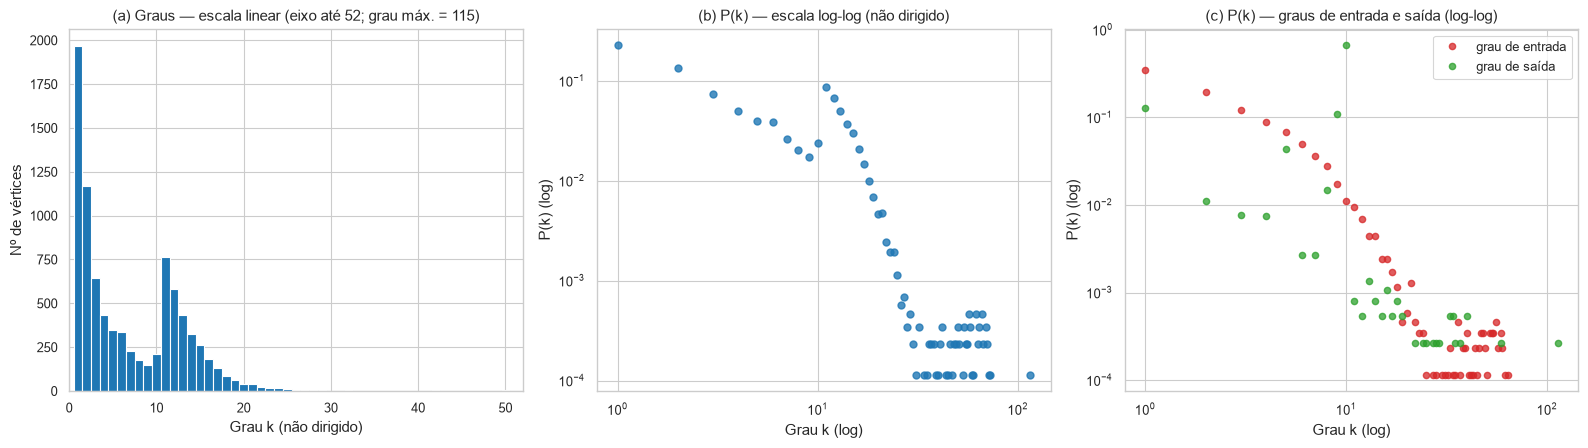

In [4]:
# Calcula a distribuição de probabilidade P(k): frequência de cada grau dividida pelo total de vértices
def pmf_grau(graus):
    c = Counter(graus.tolist())
    ks = np.array(sorted(c))
    return ks, np.array([c[k] for k in ks]) / len(graus)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) Histograma linear do grau não dirigido
axes[0].hist(tot_deg, bins=np.arange(tot_deg.min(), tot_deg.max() + 2) - 0.5, color="#1f77b4", edgecolor="white")
lim = int(np.percentile(tot_deg, 99.5)) + 2 # limita o eixo X no percentil 99,5 para a cauda longa não achatar o gráfico
axes[0].set_xlim(0, lim)
axes[0].set_title(f"(a) Graus — escala linear (eixo até {lim}; grau máx. = {tot_deg.max()})")
axes[0].set_xlabel("Grau k (não dirigido)"); axes[0].set_ylabel("Nº de vértices")

# (b) Mesma distribuição em escala log-log para evidenciar a cauda pesada
ks, pk = pmf_grau(tot_deg)
axes[1].loglog(ks, pk, "o", ms=5, alpha=0.8, color="#1f77b4")
axes[1].set_title("(b) P(k) — escala log-log (não dirigido)")
axes[1].set_xlabel("Grau k (log)"); axes[1].set_ylabel("P(k) (log)")

# (c) Graus de entrada e saída em log-log (filtra grau > 0 porque log(0) não existe)
for dados, rot, cor in [(in_deg, "entrada", "#d62728"), (out_deg, "saída", "#2ca02c")]:
    kk, pp = pmf_grau(dados[dados > 0])
    axes[2].loglog(kk, pp, "o", ms=4.5, alpha=0.75, color=cor, label=f"grau de {rot}")
axes[2].set_title("(c) P(k) — graus de entrada e saída (log-log)")
axes[2].set_xlabel("Grau k (log)"); axes[2].set_ylabel("P(k) (log)"); axes[2].legend()

# Salva o gráfico em alta resolução para o artigo
plt.tight_layout()
plt.savefig(FIGURES_DIR / "parte1_distribuicao_graus.png", dpi=300, bbox_inches="tight")
plt.show()

### 2.2 Visualização (versão reduzida)

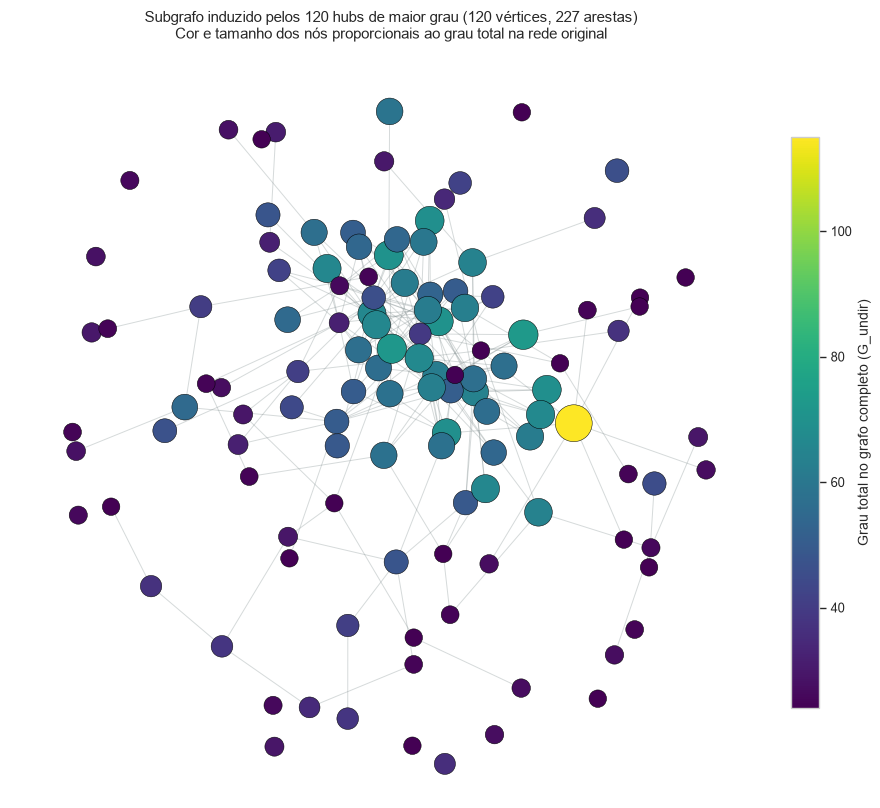

In [5]:
# Seleciona os 120 vértices mais conectados (desempatando pelo ID) e cria o subgrafo entre eles
top = [u for u, _ in sorted(G_undir.degree(), key=lambda x: (-x[1], x[0]))[:120]]
H = G_undir.subgraph(top)

# Calcula o layout de forças com semente fixa e guarda o grau original de cada nó
pos = nx.spring_layout(H, seed=SEED, k=0.35)
graus_H = [G_undir.degree(u) for u in H]

# Desenha primeiro as arestas bem suaves para não poluir e depois os nós escalados pelo grau
fig, ax = plt.subplots(figsize=(9.5, 8.2))
nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.32, width=0.7, edge_color="#7f8c8d")
nodes = nx.draw_networkx_nodes(
    H, pos, ax=ax,
    node_size=[15 + 6 * g for g in graus_H],
    node_color=graus_H,
    cmap="viridis",
    edgecolors="black",
    linewidths=0.35
)

# Adiciona a barra lateral para servir de legenda da escala de cores
cbar = plt.colorbar(nodes, ax=ax, shrink=0.76, pad=0.02)
cbar.set_label("Grau total no grafo completo (G_undir)", fontsize=10)

# Configura o título, esconde os eixos cartesianos e salva a figura
ax.set_title(
    f"Subgrafo induzido pelos 120 hubs de maior grau ({H.number_of_nodes()} vértices, {H.number_of_edges()} arestas)\n"
    "Cor e tamanho dos nós proporcionais ao grau total na rede original",
    fontsize=11
)
ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "parte1_visualizacao_top120.png", dpi=300, bbox_inches="tight")
plt.show()

### 2.3 Tabela de controle e validação com o SNAP

In [6]:
# Evita que o pandas corte textos longos das colunas com "..." ao mostrar a tabela
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

# Monta a tabela para referência no trabalho e exporta
tabela_controle = pd.DataFrame([
    {"Métrica": "Número de vértices", "Computada?": "Sim", "Valor / Observação": f"{n_vertices}"},
    {"Métrica": "Número de arestas", "Computada?": "Sim", "Valor / Observação": f"{n_arestas_dir} (dir.) | {n_arestas_undir} (não dir.)"},
    {"Métrica": "Grau mínimo, máximo e médio", "Computada?": "Sim",
     "Valor / Observação": f"Não dir.: {tot_deg.min()} / {tot_deg.max()} / {tot_deg.mean():.2f} | "
                           f"Entrada: {in_deg.min()} / {in_deg.max()} / {in_deg.mean():.2f} | "
                           f"Saída: {out_deg.min()} / {out_deg.max()} / {out_deg.mean():.2f}"},
    {"Métrica": "Distribuição de graus", "Computada?": "Sim", "Valor / Observação": "Figura parte1_distribuicao_graus.png (linear e log-log)"},
    {"Métrica": "Densidade", "Computada?": "Sim", "Valor / Observação": f"{dens_dir:.6f} (dir.) | {dens_undir:.6f} (não dir.)"},
    {"Métrica": "Número de componentes conexas", "Computada?": "Sim", "Valor / Observação": f"{len(wccs)} WCC | {len(sccs)} SCC"},
    {"Métrica": "Tamanho de cada componente", "Computada?": "Sim",
     "Valor / Observação": f"WCC: {wcc_sizes[0]} | SCC: maior = {scc_sizes[0]}, {scc_dist[1]} de tamanho 1 (lista completa em results/tamanhos_componentes.csv)"},
    {"Métrica": "Diâmetro", "Computada?": "Sim (global dirigido = ∞)",
     "Valor / Observação": f"{dist_undir['diametro']} (não dir.) | {dist_scc['diametro']} (maior SCC) | ∞ (dir. global, não fortemente conexo)"},
    {"Métrica": "Raio", "Computada?": "Sim (global dirigido = ∞)",
     "Valor / Observação": f"{dist_undir['raio']} (não dir.) | {dist_scc['raio']} (maior SCC) | ∞ (dir. global)"},
    {"Métrica": "Comprimento médio dos caminhos", "Computada?": "Sim",
     "Valor / Observação": f"{dist_undir['media']:.4f} (não dir.) | {dist_scc['media']:.4f} (maior SCC) | "
                           f"{dist_dir_alc['media']:.4f} (dir., só pares alcançáveis)"},
    {"Métrica": "Coeficiente de clusterização médio", "Computada?": "Sim", "Valor / Observação": f"{clu_undir:.4f} (não dir.) | {clu_dir:.4f} (dir.)"},
    {"Métrica": "Número de triângulos", "Computada?": "Sim", "Valor / Observação": f"{n_tri} (versão não dirigida; transitividade = {transitividade:.6f})"},
    {"Métrica": "Visualização do grafo", "Computada?": "Sim (versão reduzida)", "Valor / Observação": "Subgrafo induzido dos 120 hubs (parte1_visualizacao_top120.png)"},
])
display(tabela_controle)
tabela_controle.to_csv(TABLES_DIR / "tabela_parte1_controle.csv", index=False)

# Conferência com os valores oficiais publicados na página do SNAP.
# O SNAP calcula a fração de triângulos fechados como Δ / (tríades - 2Δ), enquanto o NetworkX
# usa 3Δ / tríades, por isso ajustamos a fórmula antes de comparar.
triades_abertas_e_fechadas = round((3 * n_tri) / transitividade)
frac_tri_snap = n_tri / (triades_abertas_e_fechadas - 2 * n_tri)

snap = {"Vértices": 8717, "Arestas": 31525, "Vértices na maior WCC": 8717, "Vértices na maior SCC": 3226,
        "Arestas na maior SCC": 13589, "Clusterização média": 0.0067, "Triângulos": 1142,
        "Fração de triângulos fechados (SNAP)": 0.002717, "Diâmetro": 10, "Diâmetro efetivo (90%)": 5.3}
meu = {"Vértices": n_vertices, "Arestas": n_arestas_dir, "Vértices na maior WCC": wcc_sizes[0],
       "Vértices na maior SCC": scc_sizes[0], "Arestas na maior SCC": arestas_scc,
       "Clusterização média": round(clu_undir, 4), "Triângulos": n_tri,
       "Fração de triângulos fechados (SNAP)": round(frac_tri_snap, 6), "Diâmetro": dist_undir["diametro"],
       "Diâmetro efetivo (90%)": round(dist_undir["ef90"], 1)}

# Junta os dois dicionários numa tabela para conferir se todos os valores batem
val = pd.DataFrame({"SNAP": snap, "Calculado aqui": meu})
val["Confere?"] = [("Sim" if abs(a - b) < 1e-9 else "Não") for a, b in zip(val["SNAP"], val["Calculado aqui"])]
display(val)
val.to_csv(TABLES_DIR / "validacao_snap.csv")

,Métrica,Computada?,Valor / Observação
0,Número de vértices,Sim,8717
1,Número de arestas,Sim,31525 (dir.) | 31525 (não dir.)
2,"Grau mínimo, máximo e médio",Sim,Não dir.: 1 / 115 / 7.23 | Entrada: 0 / 64 / 3.62 | Saída: 0 / 113 / 3.62
3,Distribuição de graus,Sim,Figura parte1_distribuicao_graus.png (linear e log-log)
4,Densidade,Sim,0.000415 (dir.) | 0.000830 (não dir.)
5,Número de componentes conexas,Sim,1 WCC | 5492 SCC
6,Tamanho de cada componente,Sim,"WCC: 8717 | SCC: maior = 3226, 5491 de tamanho 1 (lista completa em results/tamanhos_componentes.csv)"
7,Diâmetro,Sim (global dirigido = ∞),"10 (não dir.) | 19 (maior SCC) | ∞ (dir. global, não fortemente conexo)"
8,Raio,Sim (global dirigido = ∞),6 (não dir.) | 12 (maior SCC) | ∞ (dir. global)
9,Comprimento médio dos caminhos,Sim,"4.5720 (não dir.) | 6.4771 (maior SCC) | 6.5720 (dir., só pares alcançáveis)"


,SNAP,Calculado aqui,Confere?
Vértices,8717.000000,8717.000000,Sim
Arestas,31525.000000,31525.000000,Sim
Vértices na maior WCC,8717.000000,8717.000000,Sim
Vértices na maior SCC,3226.000000,3226.000000,Sim
Arestas na maior SCC,13589.000000,13589.000000,Sim
Clusterização média,0.006700,0.006700,Sim
Triângulos,1142.000000,1142.000000,Sim
Fração de triângulos fechados (SNAP),0.002717,0.002717,Sim
Diâmetro,10.000000,10.000000,Sim
Diâmetro efetivo (90%),5.300000,5.300000,Sim
